# 05 · Логистический градиентный бустинг

Новая минимальная реализация в `mlproject/boosting.py`: собственный цикл обучения, логистическая потеря, shrinkage и early stopping; слабые модели — sklearn DecisionTreeRegressor.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'mlproject').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the project folder')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from mlproject.data import dataset, split
from mlproject.experiments import run


## Как устроено обучение

Начальный score — logit частоты положительного класса в train. Отрицательный градиент log loss: `y − sigmoid(score)`. Дерево аппроксимирует этот градиент; score обновляется как `score += learning_rate × tree.predict(X)`.

Метки остаются 0/1. Learning rate применяется одинаково в обучении и предсказании. Early stopping следит за validation log loss и восстанавливает лучшую длину ансамбля; если ни одно дерево не улучшило начальный baseline, ансамбль остаётся пустым.

В отличие от исходного недописанного решения здесь нет обещаний GOSS, квантования или Bayesian bootstrap: эти опции не реализованы.

,model,rate,depth,trees,val_roc_auc,accuracy,precision,recall,f1,roc_auc,brier,log_loss
0,Custom logistic boosting,0.3,2,200,0.9902,0.9737,1.000,0.9286,0.9630,0.9967,0.0259,0.1055
1,sklearn gradient boosting,0.3,2,200,0.9957,0.9649,0.975,0.9286,0.9512,0.9924,0.0304,0.1773


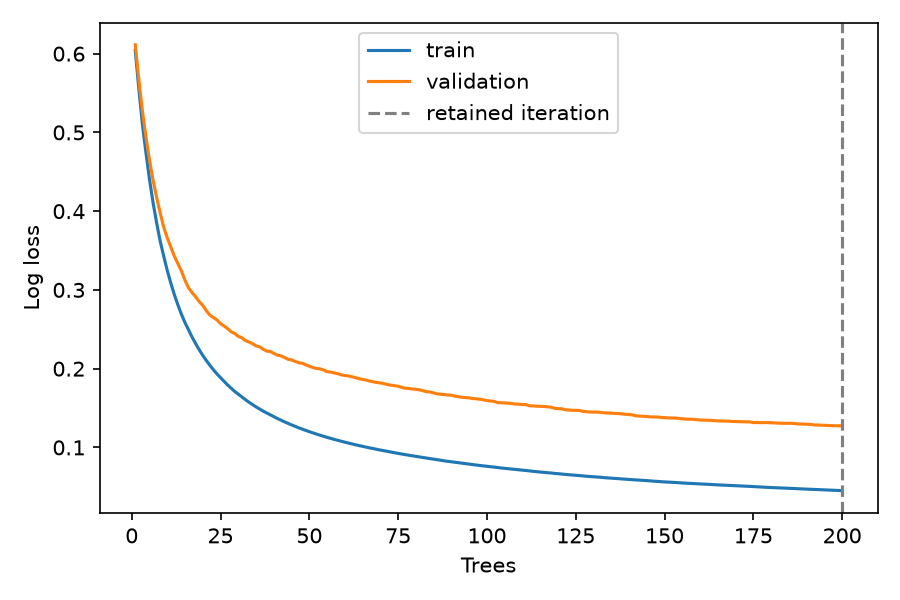

In [2]:
results=run('05')
display(results.round(4))
display(Image(filename=str(ROOT/'reports/05_boosting.png')))

## Настройка и сравнение

Для своей модели и sklearn проверяем learning rate 0.05, 0.1, 0.3 и глубины 1, 2. Свой ансамбль ограничен 200 деревьями с patience=15; sklearn обучает 200 деревьев. Это сравнение разных реализаций при ограниченной сетке, не доказательство их эквивалентности.

In [3]:
display(pd.read_csv(ROOT/'reports/05_boosting_tuning.csv').round(4))
for _,r in results.iterrows():
    print(f'{r.model}: {int(r.trees)} деревьев, test ROC-AUC={r.roc_auc:.4f}, log loss={r.log_loss:.4f}')

,model,rate,depth,val_roc_auc
0,Custom logistic boosting,0.05,1,0.9764
1,Custom logistic boosting,0.05,2,0.9731
2,Custom logistic boosting,0.10,1,0.9803
3,Custom logistic boosting,0.10,2,0.9830
4,Custom logistic boosting,0.30,1,0.9826
5,Custom logistic boosting,0.30,2,0.9902
6,sklearn gradient boosting,0.05,1,0.9846
7,sklearn gradient boosting,0.05,2,0.9928
8,sklearn gradient boosting,0.10,1,0.9908
9,sklearn gradient boosting,0.10,2,0.9934


Custom logistic boosting: 200 деревьев, test ROC-AUC=0.9967, log loss=0.1055
sklearn gradient boosting: 200 деревьев, test ROC-AUC=0.9924, log loss=0.1773


## Что проверяют тесты

Нормировку вероятностей, снижение train loss, применение learning rate, повторный fit, восстановление лучшего числа деревьев и отсутствие двойного преобразования меток. Никакие результаты из чужих сохранённых выводов не используются.